In [28]:
from pathlib import Path
import pandas as pd


In [29]:
analysis_df = pd.read_csv("eda/results/tables/analysis_df.csv")
analysis_df.head()

,Patient_ID,Sex,Age,msk_type,icd9 list,type list,comorbidity_count,msk_duration_years,mental_duration_years
0,10001000000000008,FEMALE,63.0,other_pre_existing_then_msk,"311,496,493,296,717,715,308,413","mental,respiratory,msk,circulatory",3,1.879452,6.802740
1,10001000000000019,FEMALE,72.0,other_pre_existing_then_msk,"491,271,401,496,725,715,585,250,311,733,487,30...","respiratory,endocrine,circulatory,msk,genitour...",5,4.610959,3.569863
2,10001000000000035,FEMALE,45.0,other_pre_existing_then_msk,"493,278,466,477,490,726","respiratory,endocrine,msk",2,1.531507,NaN
3,10001000000000045,MALE,49.0,other_pre_existing_then_msk,"460,604,461,473,715,311","respiratory,genitourinary,msk,mental",3,0.002740,6.147945
4,10001000000000048,FEMALE,57.0,msk_comorbidity,"715,591,307,427,240,461,455,411,493","msk,genitourinary,mental,circulatory,endocrine...",5,6.432877,6.391781


In [30]:
encounter = pd.read_csv("data/output/C4MEncounterDiagnosis_clean_1_31.csv", dtype=str)
encounter = encounter.rename(columns={"DiagnosisCode_calc": "icd9"})

encounter.head()

,EncounterDiagnosis_ID,Network_ID,Site_ID,Patient_ID,Encounter_ID,Cycle_ID,DiagnosisText_orig,DiagnosisText_calc,DiagnosisCodeType_orig,DiagnosisCodeType_calc,DiagnosisCode_orig,icd9,DateCreated,musculoskeletal_disorders
0,1002000000000002,1,1000000000000004,1002000000032183,1002000000000001.0,2015-Q2,Diabetes Mellitus -Type 1- Insulin Dependent,TYPE I DIABETES MELLITUS [INSULIN DEPENDENT TY...,ICD9,ICD9,250.01,250.01,2008-08-05,True
1,1002000000000003,1,1000000000000004,1002000000032183,1002000000000001.0,2015-Q2,Hep A and Hep B Combined Vaccine,NaN,NaN,NaN,NaN,NaN,2008-08-05,True
2,1002000000000004,1,1000000000000004,1002000000032183,1002000000000001.0,2015-Q2,Pre Natal Form,NaN,NaN,NaN,NaN,NaN,2008-08-05,True
3,1002000000000005,1,1000000000000004,1002000000013966,1002000000000004.0,2015-Q2,general symptoms genx,GENERAL SYMPTOMS,ICD9,ICD9,780,780,2008-09-04,False
4,1002000000000006,1,1000000000000004,1002000000024045,1002000000000005.0,2015-Q2,Obesity,OVERWEIGHT AND OBESITY,ICD9,ICD9,278.0,278.0,2008-09-11,True


In [31]:
analysis_df["msk_type"].value_counts()

msk_type
other_pre_existing_then_msk    100479
msk_comorbidity                 31261
co_onset                         7952
msk_only                         4644
Name: count, dtype: int64

In [32]:
subgroup_df = analysis_df[
    analysis_df["msk_type"] == "other_pre_existing_then_msk"
].copy()

In [33]:
N = subgroup_df["Patient_ID"].nunique()
print("Subgroup N =", N)

Subgroup N = 100479


In [34]:
subgroup_df[["Patient_ID", "Sex", "Age", "msk_type"]].head()

,Patient_ID,Sex,Age,msk_type
0,10001000000000008,FEMALE,63.0,other_pre_existing_then_msk
1,10001000000000019,FEMALE,72.0,other_pre_existing_then_msk
2,10001000000000035,FEMALE,45.0,other_pre_existing_then_msk
3,10001000000000045,MALE,49.0,other_pre_existing_then_msk
5,10001000000000056,MALE,18.0,other_pre_existing_then_msk


In [35]:
print("Total patients:", analysis_df["Patient_ID"].nunique())
print("Subgroup proportion:", N / analysis_df["Patient_ID"].nunique())

Total patients: 144336
Subgroup proportion: 0.6961464915197871


In [36]:
sub_ids = subgroup_df["Patient_ID"].astype("string").str.strip().unique()

In [37]:
enc_sub = encounter[
    encounter["Patient_ID"].isin(sub_ids)
].copy()

In [38]:
enc_sub.head()

,EncounterDiagnosis_ID,Network_ID,Site_ID,Patient_ID,Encounter_ID,Cycle_ID,DiagnosisText_orig,DiagnosisText_calc,DiagnosisCodeType_orig,DiagnosisCodeType_calc,DiagnosisCode_orig,icd9,DateCreated,musculoskeletal_disorders
0,1002000000000002,1,1000000000000004,1002000000032183,1002000000000001.0,2015-Q2,Diabetes Mellitus -Type 1- Insulin Dependent,TYPE I DIABETES MELLITUS [INSULIN DEPENDENT TY...,ICD9,ICD9,250.01,250.01,2008-08-05,True
1,1002000000000003,1,1000000000000004,1002000000032183,1002000000000001.0,2015-Q2,Hep A and Hep B Combined Vaccine,NaN,NaN,NaN,NaN,NaN,2008-08-05,True
2,1002000000000004,1,1000000000000004,1002000000032183,1002000000000001.0,2015-Q2,Pre Natal Form,NaN,NaN,NaN,NaN,NaN,2008-08-05,True
4,1002000000000006,1,1000000000000004,1002000000024045,1002000000000005.0,2015-Q2,Obesity,OVERWEIGHT AND OBESITY,ICD9,ICD9,278.0,278.0,2008-09-11,True
6,1002000000000008,1,1000000000000004,1002000000005174,1002000000000007.0,2015-Q2,Esophageal Cancer,MALIGNANT NEOPLASM OF ESOPHAGUS,ICD9,ICD9,150,150,2008-09-05,True


In [39]:
from __future__ import annotations
from typing import Iterable, Optional, Tuple
import pandas as pd


def compute_first_msk_date(
    encounter: pd.DataFrame,
    patient_ids: Optional[Iterable[str]] = None,
    *,
    patient_col: str = "Patient_ID",
    date_col: str = "DateCreated",
    icd9_col: str = "icd9",
    msk_range: Tuple[float, float] = (710, 739.9),
    rename_diagnosis_col: Optional[str] = None,  # e.g. "DiagnosisCode_calc"
    verbose: bool = True,
) -> pd.DataFrame:
    """
    Compute first MSK diagnosis date per patient from encounter-level diagnosis data.

    Parameters
    ----------
    encounter : pd.DataFrame
        Must contain patient_col, date_col, icd9_col (or provide rename_diagnosis_col).
    patient_ids : iterable[str] | None
        If provided, restrict computation to these patients (recommended for subgroup).
    patient_col, date_col, icd9_col : str
        Column names.
    msk_range : (float, float)
        Numeric ICD9 range for MSK (default 710–739.9).
    rename_diagnosis_col : str | None
        If your raw encounter has diagnosis in another column name, pass it here to rename to icd9_col.
        Example: rename_diagnosis_col="DiagnosisCode_calc"
    verbose : bool
        Print basic QC.

    Returns
    -------
    pd.DataFrame with columns: [patient_col, "first_msk_date"]
    """
    df = encounter.copy()


    # Validate required columns
    required = [patient_col, date_col, icd9_col]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise KeyError(f"encounter missing columns: {missing}")

    # Normalize patient IDs and dates
    df[patient_col] = df[patient_col].astype("string").str.strip()
    df[date_col] = pd.to_datetime(df[date_col], errors="coerce")

    # Restrict to subgroup patients if provided
    if patient_ids is not None:
        pid = pd.Series(list(patient_ids), dtype="string").str.strip().unique()
        df = df[df[patient_col].isin(pid)].copy()

    # Extract numeric ICD9 for range filtering
    icd9_num = (
        df[icd9_col]
        .astype("string")
        .str.strip()
        .str.extract(r"(\d+\.?\d*)")[0]
    )
    df["icd9_num"] = pd.to_numeric(icd9_num, errors="coerce")

    # Filter MSK ICD9 range
    lo, hi = msk_range
    msk_mask = df["icd9_num"].between(lo, hi, inclusive="both")

    df_msk = df.loc[msk_mask].dropna(subset=[patient_col, date_col])

    # First MSK date per patient
    first_msk = (
        df_msk.groupby(patient_col)[date_col]
        .min()
        .reset_index()
        .rename(columns={date_col: "first_msk_date"})
    )

    if verbose:
        n_pat = df[patient_col].nunique()
        n_msk_pat = first_msk[patient_col].nunique()
        icd9_na_rate = df["icd9_num"].isna().mean()
        date_na_rate = df[date_col].isna().mean()
        print(f"[compute_first_msk_date] patients in scope: {n_pat}")
        print(f"[compute_first_msk_date] patients with MSK: {n_msk_pat} ({n_msk_pat / max(n_pat,1):.3%})")
        print(f"[compute_first_msk_date] icd9 numeric parse NA rate: {icd9_na_rate:.3%}")
        print(f"[compute_first_msk_date] date parse NA rate: {date_na_rate:.3%}")

    return first_msk[[patient_col, "first_msk_date"]]

In [40]:
sub_ids = subgroup_df["Patient_ID"].astype("string").str.strip().unique()

first_msk = compute_first_msk_date(
    encounter,
    patient_ids=sub_ids,
    verbose=True
)

first_msk.head()

[compute_first_msk_date] patients in scope: 100479
[compute_first_msk_date] patients with MSK: 100479 (100.000%)
[compute_first_msk_date] icd9 numeric parse NA rate: 15.736%
[compute_first_msk_date] date parse NA rate: 0.000%


,Patient_ID,first_msk_date
0,10001000000000008,2013-01-17
1,10001000000000019,2010-10-04
2,10001000000000035,2013-07-24
3,10001000000000045,2007-05-15
4,10001000000000056,2014-01-09


In [41]:

enc_sub["Patient_ID"] = enc_sub["Patient_ID"].astype("string").str.strip()
enc_sub["DateCreated"] = pd.to_datetime(enc_sub["DateCreated"], errors="coerce")

enc_sub = enc_sub[enc_sub["Patient_ID"].isin(sub_ids)].copy()
enc_sub = enc_sub.merge(first_msk, on="Patient_ID", how="left")

enc_pre = enc_sub[enc_sub["DateCreated"] < enc_sub["first_msk_date"]].copy()

In [42]:
enc_pre.head()

,EncounterDiagnosis_ID,Network_ID,Site_ID,Patient_ID,Encounter_ID,Cycle_ID,DiagnosisText_orig,DiagnosisText_calc,DiagnosisCodeType_orig,DiagnosisCodeType_calc,DiagnosisCode_orig,icd9,DateCreated,musculoskeletal_disorders,first_msk_date
0,1002000000000002,1,1000000000000004,1002000000032183,1002000000000001.0,2015-Q2,Diabetes Mellitus -Type 1- Insulin Dependent,TYPE I DIABETES MELLITUS [INSULIN DEPENDENT TY...,ICD9,ICD9,250.01,250.01,2008-08-05,True,2008-08-12
1,1002000000000003,1,1000000000000004,1002000000032183,1002000000000001.0,2015-Q2,Hep A and Hep B Combined Vaccine,NaN,NaN,NaN,NaN,NaN,2008-08-05,True,2008-08-12
2,1002000000000004,1,1000000000000004,1002000000032183,1002000000000001.0,2015-Q2,Pre Natal Form,NaN,NaN,NaN,NaN,NaN,2008-08-05,True,2008-08-12
3,1002000000000006,1,1000000000000004,1002000000024045,1002000000000005.0,2015-Q2,Obesity,OVERWEIGHT AND OBESITY,ICD9,ICD9,278.0,278.0,2008-09-11,True,2014-05-08
4,1002000000000008,1,1000000000000004,1002000000005174,1002000000000007.0,2015-Q2,Esophageal Cancer,MALIGNANT NEOPLASM OF ESOPHAGUS,ICD9,ICD9,150,150,2008-09-05,True,2011-03-01


In [49]:


def build_icd9_name_map(encounter: pd.DataFrame,
                        icd9_col: str = "icd9",
                        name_col: str = "DiagnosisText_calc") -> dict:
    df = encounter.copy()
    df[icd9_col] = df[icd9_col].astype("string").str.strip()
    df[name_col] = df[name_col].astype("string").str.strip()

    # 去掉缺失
    df = df.dropna(subset=[icd9_col, name_col])

    # 对每个 icd9，取出现次数最多的名字
    name_map = (
        df.groupby(icd9_col)[name_col]
        .agg(lambda s: s.value_counts().index[0])
        .to_dict()
    )
    return name_map

# 使用：如果 encounter 还没 rename
# encounter = encounter.rename(columns={"DiagnosisCode_calc":"icd9"})
icd9_to_name = build_icd9_name_map(encounter, icd9_col="icd9", name_col="DiagnosisText_calc")

In [50]:
def format_icd9_list_with_names(icd9_list_str: str, name_map: dict, keep_unknown: bool = True) -> str:
    if pd.isna(icd9_list_str) or str(icd9_list_str).strip() == "":
        return ""
    codes = [c.strip() for c in str(icd9_list_str).split(",") if c.strip() != ""]
    out = []
    for code in codes:
        name = name_map.get(code)
        if name is None:
            if keep_unknown:
                out.append(f"{code} (Unknown)")
        else:
            out.append(f"{code} ({name})")
    return ", ".join(out)

analysis_df2 = analysis_df.copy()

analysis_df2["icd9 list (named)"] = analysis_df2["icd9 list"].apply(
    lambda s: format_icd9_list_with_names(s, icd9_to_name)
)

analysis_df2[["Patient_ID", "icd9 list", "icd9 list (named)", "type list"]].head()

,Patient_ID,icd9 list,icd9 list (named),type list
0,10001000000000008,"311,496,493,296,717,715,308,413","311 (DEPRESSIVE DISORDER, NOT ELSEWHERE CLASSI...","mental,respiratory,msk,circulatory"
1,10001000000000019,"491,271,401,496,725,715,585,250,311,733,487,30...","491 (CHRONIC BRONCHITIS), 271 (DISORDERS OF CA...","respiratory,endocrine,circulatory,msk,genitour..."
2,10001000000000035,"493,278,466,477,490,726","493 (ASTHMA), 278 (OVERWEIGHT, OBESITY AND OTH...","respiratory,endocrine,msk"
3,10001000000000045,"460,604,461,473,715,311","460 (ACUTE NASOPHARYNGITIS [COMMON COLD]), 604...","respiratory,genitourinary,msk,mental"
4,10001000000000048,"715,591,307,427,240,461,455,411,493","715 (OSTEOARTHROSIS AND ALLIED DISORDERS), 591...","msk,genitourinary,mental,circulatory,endocrine..."


In [48]:


def mental_subtype_common(icd9: str) -> str:
    s = str(icd9).strip()
    # Depression (core)
    if s.startswith("296.2") or s.startswith("296.3") or s == "311" or s.startswith("311.") or s.startswith("300.4"):
        return "depression"
    # Anxiety (core)
    if s.startswith("300.0") or s.startswith("300.2"):
        return "anxiety"
    return "other_mental"


# --- prepare numeric icd9 and filter mental range (290-319) ---
df = enc_pre.copy()
df["icd9"] = df["icd9"].astype("string").str.strip()
df["icd9_num"] = pd.to_numeric(df["icd9"].str.extract(r"(\d+\.?\d*)")[0], errors="coerce")
df = df.dropna(subset=["Patient_ID", "icd9_num"])

mental_pre = df[df["icd9_num"].between(290, 319, inclusive="both")].copy()

# --- subtype ---
mental_pre["mental_subtype"] = mental_pre["icd9"].apply(mental_subtype_common)

mental_pre["mental_subtype"].value_counts()

mental_subtype
other_mental    68343
depression      51323
anxiety         28780
Name: count, dtype: int64

In [43]:


enc_pre2 = enc_pre.copy()

# 保证 icd9 是 string
enc_pre2["icd9"] = enc_pre2["icd9"].astype("string").str.strip()

# 提取 3-digit ICD9
enc_pre2["icd9_3digit"] = enc_pre2["icd9"].str.extract(r"(\d{3})")[0]

# 去掉没有 ICD9 的记录
enc_pre2 = enc_pre2.dropna(subset=["icd9_3digit"])
enc_pre2["icd9_3digit"].head()

0    250
3    278
4    150
5    784
7    272
Name: icd9_3digit, dtype: string

In [44]:
N = subgroup_df["Patient_ID"].nunique()

top_icd3 = (
    enc_pre2.groupby("icd9_3digit")["Patient_ID"]
    .nunique()
    .sort_values(ascending=False)
    .rename("n_patients")
    .to_frame()
    .reset_index()
)

top_icd3["pct_patients"] = top_icd3["n_patients"] / N * 100

top_icd3.head(20)

,icd9_3digit,n_patients,pct_patients
0,401,25994,25.870082
1,780,21239,21.137750
2,300,18387,18.299346
3,272,15625,15.550513
4,786,14397,14.328367
5,311,13726,13.660566
6,461,10286,10.236965
7,789,10254,10.205117
8,465,10205,10.156351
9,250,9634,9.588073


In [45]:
icd3_name = (
    enc_pre2.dropna(subset=["DiagnosisText_calc"])
    .groupby("icd9_3digit")["DiagnosisText_calc"]
    .agg(lambda s: s.value_counts().index[0])  # 最常见的名字
    .rename("name")
    .reset_index()
)

top_icd3_named = top_icd3.merge(icd3_name, on="icd9_3digit", how="left")

top_icd3_named[["icd9_3digit", "name", "n_patients", "pct_patients"]].head(20)

,icd9_3digit,name,n_patients,pct_patients
0,401,UNSPECIFIED ESSENTIAL HYPERTENSION,25994,25.870082
1,780,GENERAL SYMPTOMS,21239,21.137750
2,300,"ANXIETY, DISSOCIATIVE AND SOMATOFORM DISORDERS",18387,18.299346
3,272,DISORDERS OF LIPOID METABOLISM,15625,15.550513
4,786,COUGH,14397,14.328367
5,311,"DEPRESSIVE DISORDER, NOT ELSEWHERE CLASSIFIED",13726,13.660566
6,461,ACUTE SINUSITIS,10286,10.236965
7,789,ABDOMINAL PAIN,10254,10.205117
8,465,ACUTE UPPER RESPIRATORY INFECTIONS OF UNSPECIF...,10205,10.156351
9,250,DIABETES MELLITUS,9634,9.588073


/var/folders/44/d1_ldkqx26d6t0zpytcn9qf00000gn/T/ipykernel_16705/1299328649.py:15: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


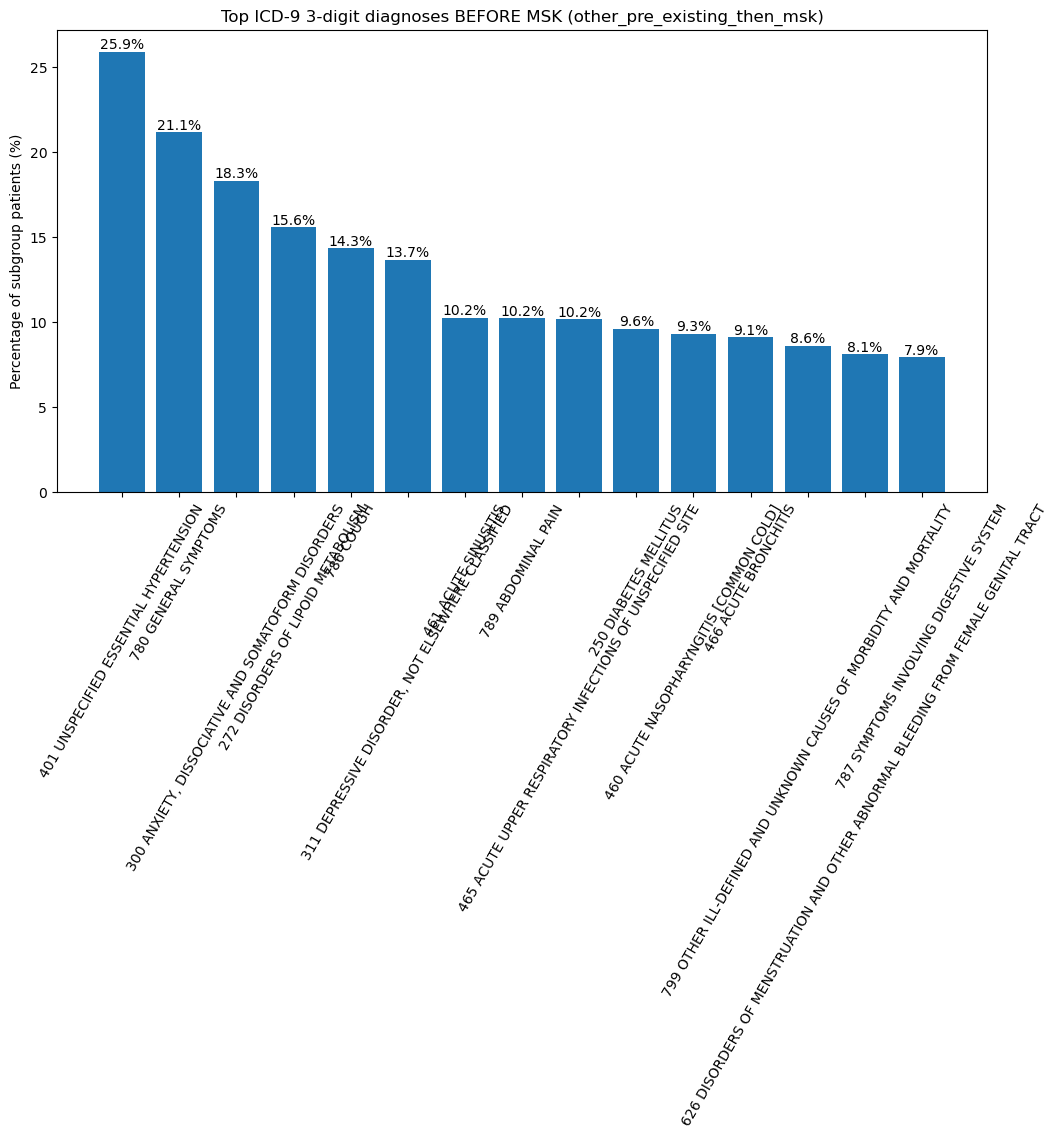

In [46]:
import matplotlib.pyplot as plt

dfp = top_icd3_named.head(15).copy()
labels = dfp["icd9_3digit"].astype(str) + " " + dfp["name"].fillna("")

fig, ax = plt.subplots(figsize=(12,6))
ax.bar(labels, dfp["pct_patients"])
ax.set_title("Top ICD-9 3-digit diagnoses BEFORE MSK (other_pre_existing_then_msk)")
ax.set_ylabel("Percentage of subgroup patients (%)")
ax.tick_params(axis="x", rotation=60)

for i, v in enumerate(dfp["pct_patients"].values):
    ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom")

plt.tight_layout()
plt.show()